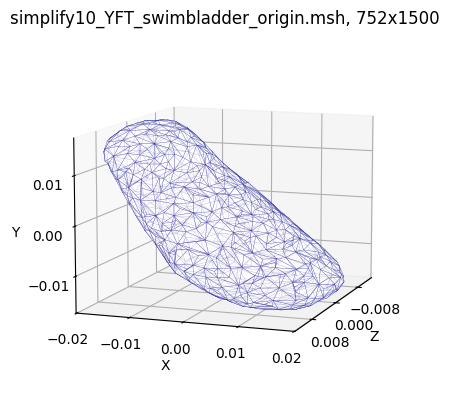

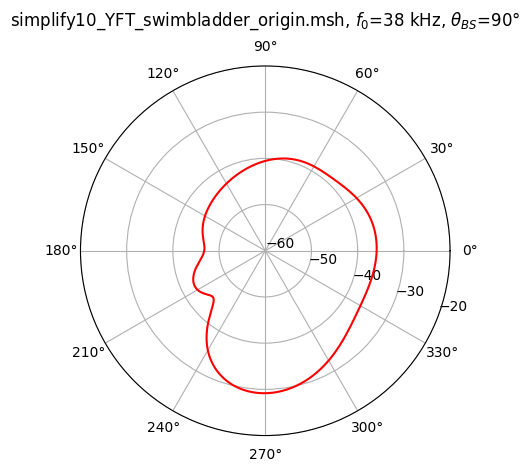

# simplify10_YFT_swimbladder_origin.msh
# th0=270 ph0=0 f0=38000 c0=1480
0	0.0160478
1	0.0160697
2	0.0160865
3	0.0160979
4	0.0161035
5	0.0161028
6	0.0160957
7	0.0160817
8	0.0160607
9	0.0160324
10	0.0159966
11	0.0159532
12	0.015902
13	0.015843
14	0.0157762
15	0.0157015
16	0.0156191
17	0.0155291
18	0.0154316
19	0.0153269
20	0.0152153
21	0.0150971
22	0.0149728
23	0.0148427
24	0.0147075
25	0.0145676
26	0.0144238
27	0.0142766
28	0.0141267
29	0.0139749
30	0.0138221
31	0.0136688
32	0.0135161
33	0.0133646
34	0.0132153
35	0.0130688
36	0.012926
37	0.0127876
38	0.0126543
39	0.0125268
40	0.0124054
41	0.0122909
42	0.0121834
43	0.0120833
44	0.0119909
45	0.011906
46	0.0118288
47	0.0117591
48	0.0116965
49	0.0116409
50	0.0115917
51	0.0115485
52	0.0115107
53	0.0114776
54	0.0114486
55	0.011423
56	0.0114
57	0.011379
58	0.0113593
59	0.01134
60	0.0113207
61	0.0113007
62	0.0112793
63	0.0112561
64	0.0112305
65	0.0112022
66	0.0111707
67	0.0111359
68	0.0110973
69	0.0110549
70	0.0110085
71	0.010958
72	0.0109033


In [22]:
# MM 19.5.2025: scattering from soft body
# !pip install numpy torch matplotlib

# plane wave scattering from soft target in salt water
# input: msh ascii 2.2 file
# output: 1-deg scattering pattern
# Optimized for PyTorch GPU (MPS/CUDA) with CPU fallback for Complex Solvers
#import sys
import torch
from numpy import log10, array, linspace

# MPS (Apple Silicon), CUDA (NVIDIA, CPU fallback
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

pi = torch.pi
datapath="../msh/"

# input parameters
fname = 'Yellowfin_Tuna_752x1500.msh' #if len(sys.argv)<=1 else sys.argv[1]
fname = 'sphere-1.905_4098x8092.msh'  #if len(sys.argv)<=1 else sys.argv[1]
fname = 'sphere-1.905-600.msh'
fname = 'simplify10_YFT_swimbladder_origin.msh'
# fname = 'YFT_swimbladder_origin.msh'
th = 270   #if len(sys.argv)<=2 else float(sys.argv[2])
f0 = 38e3  #if len(sys.argv)<=3 else float(sys.argv[3])
c0 = 1480  #if len(sys.argv)<=4 else float(sys.argv[4])
ph = 0     #if len(sys.argv)<=5 else float(sys.argv[5])

k = 2 * pi * f0 / c0

#  GPU (MPS float32)
Ry = torch.tensor([
    [torch.cos(torch.tensor(ph*pi/180)), 0, torch.sin(torch.tensor(ph*pi/180))],
    [0, 1, 0],
    [-torch.sin(torch.tensor(ph*pi/180)), 0, torch.cos(torch.tensor(ph*pi/180))]
], dtype=torch.float32, device=device)
d = Ry @ torch.tensor([torch.cos(torch.tensor(th*pi/180+pi)), torch.sin(torch.tensor(th*pi/180+pi)), 0], dtype=torch.float32, device=device)

with open(datapath + fname) as f: lines = f.readlines()
n = int(lines[4])
v = [list(map(float, lines[5+i].split()[1:4])) for i in range(n)]
m = int(lines[n+7])
e = [list(map(lambda x: int(x)-1, lines[n+8+i].split()[5:8])) for i in range(m)]

# GPU
v = torch.tensor(v, dtype=torch.float32, device=device)
e = torch.tensor(e, dtype=torch.long, device=device)
x = v[e].mean(dim=1)  # shape: (m, 3)
#x, m = v, len(v)
diff = x.unsqueeze(1) - x.unsqueeze(0)  # Kształt: (m, m, 3)
r = torch.norm(diff, dim=2)             # Kształt: (m, m)
S = torch.empty((m, m), dtype=torch.complex64, device=device)
mask_zero = (r == 0)
mask_nonzero = ~mask_zero
r_nz = r[mask_nonzero].to(torch.complex64)
S[mask_nonzero] = torch.exp(1j * k * r_nz) / r_nz / (4 * pi)
S[mask_zero] = k / 4 + 1j * k / (4 * pi)
f_vec = torch.exp(1j * k * (x @ d))

S_cpu = S.cpu()          # copy S, f_vec to CPU
f_vec_cpu = f_vec.cpu()
phi_cpu = torch.linalg.solve(S_cpu, -f_vec_cpu)
phi = phi_cpu.to(device) # phi back to GPU

# Far field: GPU
angles = torch.arange(360, dtype=torch.float32, device=device) * pi / 180 + pi
r1_vectors = torch.stack([torch.cos(angles), torch.sin(angles), torch.zeros_like(angles)], dim=1)
r1 = r1_vectors @ Ry.T  # (360, 3)
S_far = torch.exp(-1j * k * (r1 @ x.T)) / (4 * pi)
psc = S_far @ phi             # GPU: matrix-vector
psc = psc.cpu().abs().numpy() # to CPU

#print("\n".join(["%d\t%.6f" % (i, psc[i]) for i in range(len(psc))]))

# plot mesh
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
tri = [[array(v[i].cpu().numpy()) for i in t] for t in e]
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
mesh_collection = Poly3DCollection(tri, alpha=0.6)
mesh_collection.set_facecolor('white')
mesh_collection.set_edgecolor('darkblue')
mesh_collection.set_linewidth(0.2)
ax.add_collection3d(mesh_collection)
v_arr = array(v.cpu().numpy())
x_min, x_max = v_arr[:, 0].min(), v_arr[:, 0].max()
y_min, y_max = v_arr[:, 1].min(), v_arr[:, 1].max()
z_min, z_max = v_arr[:, 2].min(), v_arr[:, 2].max()
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_zlim(z_min, z_max)
x_range = x_max - x_min
y_range = y_max - y_min
z_range = z_max - z_min
ax.set_box_aspect((x_range, y_range, z_range))
ax.view_init(elev=10, azim=20, vertical_axis='y')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title(r"%s, %dx%d"%(fname,n,m))
from matplotlib.ticker import MaxNLocator
ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
ax.zaxis.set_major_locator(MaxNLocator(nbins=4))
plt.savefig("yft_torch_1.svg", format="svg", bbox_inches="tight")
plt.show()

# plot solution
import matplotlib.pyplot as plt
angles = linspace(0, 2 * pi, 360, endpoint=False)
values_db = 20 * log10([abs(p) for p in psc])
vmin, vmax = -60, -20
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(angles, values_db, color='red')
ax.set_ylim(vmin, vmax)
ax.set_rticks(linspace(vmin, vmax, 5))
ax.set_xticks(linspace(0, 2*pi-pi/6, 12))  # 30deg
ax.set_rlabel_position(-20)
ax.grid(True)
ax.set_title(r"%s, $f_0$=%g kHz, $\theta_{BS}$=%g$\degree$"%(fname,f0/1e3,(th+180)%360), va='bottom')
plt.savefig("yft_torch_2.svg", format="svg", bbox_inches="tight")
plt.show()

# print
s = "# %s\n# th0=%g ph0=0 f0=%g c0=%g\n"%(fname,th,f0,c0)
s += "\n".join(["%d\t%g"%(i,abs(psc[i])) for i in range(len(psc))])
print(s)
with open("yft_torch_3.txt", "w") as f: print(s,file=f)